# Data Workflow: Titanic Survival Analysis

**Author:** Sandip Dey  
**Dataset:** Titanic - Machine Learning from Disaster  
**Source:** https://www.kaggle.com/c/titanic  
**GitHub Repository:** https://github.com/sandipdey2/ai-programming-foundations-project

This notebook implements a complete, reproducible data workflow: loading, cleaning, exploratory analysis, visualization, and interpretation.


## 1. Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("titanic.csv")
print(f"Dataset shape: {df.shape}")
print("\nFirst rows:")
df.head()


Dataset shape: (891, 12)

First rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Cleaning Functions

In [2]:
def handle_missing_values(df):
    """
    Handle missing values in the Titanic dataset.
    
    Age is filled with the median. Embarked is filled with the mode.
    Cabin is dropped because it is mostly missing.
    
    Parameters
    ----------
    df : pandas.DataFrame
        Raw input DataFrame.
    
    Returns
    -------
    pandas.DataFrame
        DataFrame with missing values addressed.
    """
    df = df.copy()
    df["Age"] = df["Age"].fillna(df["Age"].median())
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
    if "Cabin" in df.columns:
        df = df.drop(columns=["Cabin"])
    return df


def remove_irrelevant_columns(df):
    """
    Remove columns that are not useful for analysis or modeling.
    
    PassengerId, Name, and Ticket are identifiers or high-cardinality
    text fields that do not contribute to statistical exploration.
    
    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame.
    
    Returns
    -------
    pandas.DataFrame
        DataFrame with irrelevant columns removed.
    """
    df = df.copy()
    columns_to_drop = ["PassengerId", "Name", "Ticket"]
    existing = [c for c in columns_to_drop if c in df.columns]
    return df.drop(columns=existing)


# Apply cleaning
df = handle_missing_values(df)
df = remove_irrelevant_columns(df)
print("After cleaning:")
print(df.info())
print(df.head())


After cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB
None
   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


**Cleaning justification:**  
- `handle_missing_values` addresses missing Age (median imputation), missing Embarked (mode imputation), and the mostly-empty Cabin column (dropped).  
- `remove_irrelevant_columns` removes identifier and high-cardinality text columns that do not support analysis.


## 3. Exploratory Analysis Function

In [3]:
def exploratory_summary(df):
    """
    Produce a concise exploratory summary of the cleaned dataset.
    
    Returns summary statistics, survival rates by class and sex,
    and basic correlation information.
    
    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned DataFrame.
    
    Returns
    -------
    None
        Prints summary information.
    """
    print("Summary statistics:")
    print(df.describe())
    print("\nSurvival rate by Pclass:")
    print(df.groupby("Pclass")["Survived"].mean())
    print("\nSurvival rate by Sex:")
    print(df.groupby("Sex")["Survived"].mean())
    print("\nOverall survival rate:", df["Survived"].mean())

exploratory_summary(df)


Summary statistics:
         Survived      Pclass         Age       SibSp       Parch        Fare
count  891.000000  891.000000  891.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.361582    0.523008    0.381594   32.204208
std      0.486592    0.836071   13.019697    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   22.000000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   35.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200

Survival rate by Pclass:
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

Survival rate by Sex:
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Overall survival rate: 0.3838383838383838


## 4. Visualizations

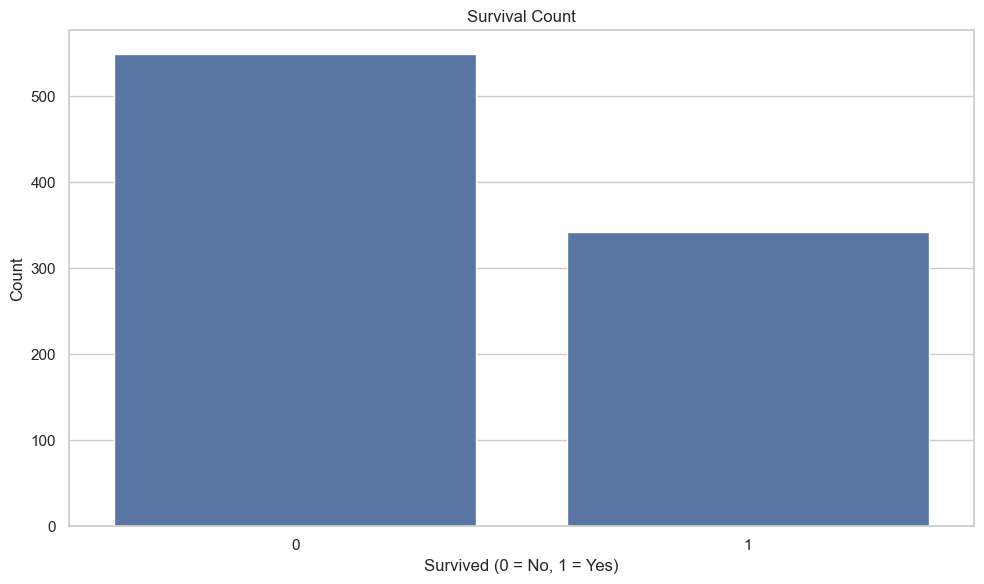

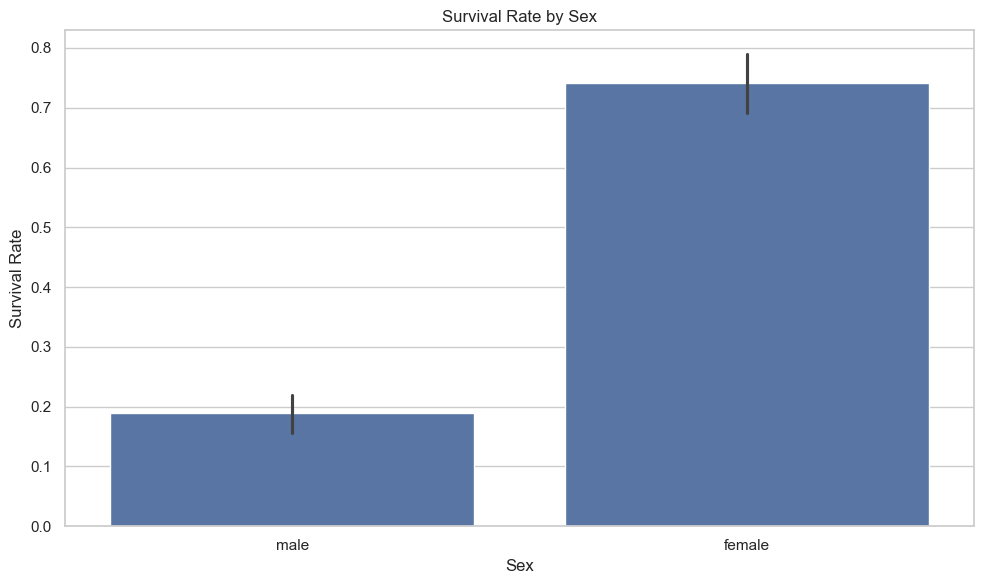

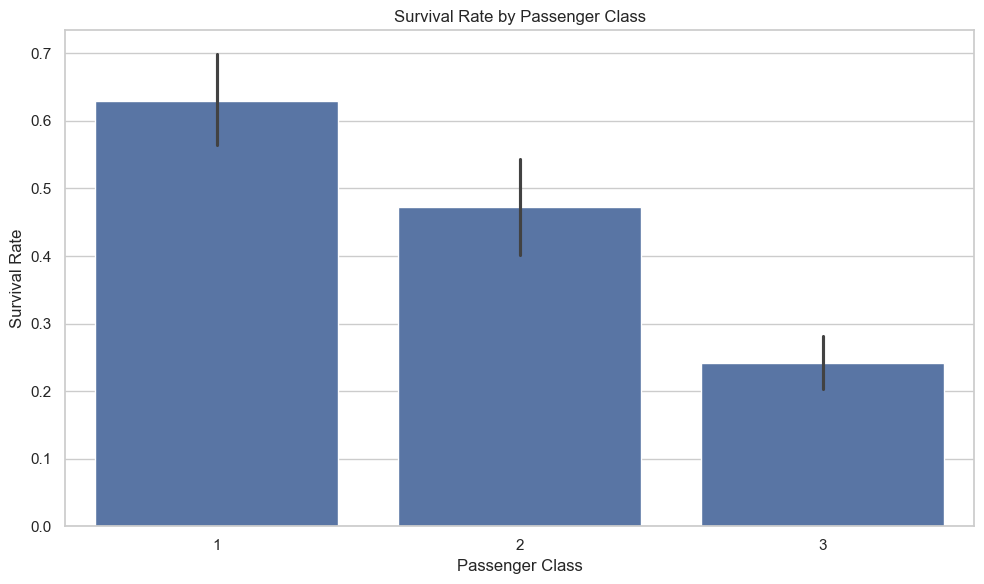

In [4]:
# Figure 1: Survival count
plt.figure()
sns.countplot(data=df, x="Survived")
plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Figure 2: Survival by Sex
plt.figure()
sns.barplot(data=df, x="Sex", y="Survived")
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

# Figure 3: Survival by Passenger Class
plt.figure()
sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()


## 5. Summary

The cleaned Titanic dataset contains 891 passengers after removing irrelevant columns and addressing missing values. Survival was higher for females than males and higher for first-class passengers than third-class passengers. Age was imputed with the median to preserve sample size. These patterns are consistent across the descriptive statistics and the three visualizations. Limitations include the historical nature of the data and the absence of cabin information after cleaning.
